In [54]:
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
from dask.diagnostics import ProgressBar
import datetime
import os, glob

import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [55]:
import matplotlib as mpl
import matplotlib.font_manager as fm

FONT_DIR = os.path.expanduser("~/fonts/SourceSans3")

for f in glob.glob(os.path.join(FONT_DIR, "*.ttf")):
    fm.fontManager.addfont(f)

available = {f.name for f in fm.fontManager.ttflist}
FAMILY = next((n for n in ("Source Sans 3", "Source Sans Pro") if n in available), None)
if FAMILY is None:
    raise RuntimeError(f"Source Sans not found. Check FONT_DIR: {FONT_DIR}")

W = 418.25372 / 72.27   # \textwidth in inches (~5.787)
W_HALF = 0.48 * W       # two panels side by side

mpl.rcParams.update({
    # --- Text / fonts ---
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": [FAMILY],
    "mathtext.fontset": "custom",
    "mathtext.rm": FAMILY,
    "mathtext.it": f"{FAMILY}:italic",
    "mathtext.bf": f"{FAMILY}:bold",
    "mathtext.sf": FAMILY,
    "mathtext.default": "it",
    "mathtext.fallback": "cm",     
    "axes.unicode_minus": True,    

    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.titlesize": 10,

    "axes.linewidth": 0.8,
    "lines.linewidth": 1.3,
    "lines.markersize": 4,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.4,

    "legend.frameon": False,
    "legend.handlelength": 1.5,

    "figure.figsize": (W, W),
    "figure.constrained_layout.use": True,
    "savefig.dpi": 300,             
    "savefig.format": "pdf",
    "pdf.fonttype": 42,    
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

In [56]:
years = np.arange(1991, 2021, 1)

In [57]:
filename_lh_flux = [f'/jetfs/scratch/psplechtna/flexpart_output/oper/{year}/processed_data/lh_50.zarr' for year in years]
filename_sh_flux = [f'/jetfs/scratch/psplechtna/flexpart_output/oper/{year}/processed_data/sh_50.zarr' for year in years]

In [58]:
def deg_to_rad(angle):
    return angle*np.pi/180

def grid_cell_area(lon_width, lat_width, radius, lower_lat):
    a = radius**2 * deg_to_rad(lon_width) * (np.sin(deg_to_rad(lower_lat+lat_width)) - np.sin(deg_to_rad(lower_lat)))
    return a

In [59]:
r = 6371e3 # radius of the Earth in m
res = 0.5  # resolution of the grid in degrees
cp = 1005.  


## for full 30 years

In [60]:
with ProgressBar():
    lh_flux = xr.open_mfdataset(filename_lh_flux, engine='zarr').isel(time=slice(None, None, -1)).lh_50
    sh_flux = xr.open_mfdataset(filename_sh_flux, engine='zarr').isel(time=slice(None, None, -1)).sh_50


In [129]:
int_lh = xr.open_dataset('/jetfs/scratch/psplechtna/int_lh.nc')
int_sh = xr.open_dataset('/jetfs/scratch/psplechtna/int_lh.nc')

In [ ]:
#with ProgressBar():
#    int_lh = (lh_flux.sum(dim=['time'])/(len(lh_flux.pointspec)*len(years))).load()
#    int_sh = (sh_flux.sum(dim=['time'])/(len(lh_flux.pointspec)*len(years))).load()

[########################################] | 100% Completed | 25m 4ss
[########################################] | 100% Completed | 24m 36s


In [127]:
int_lh_aug = int_lh.isel(pointspec=slice(-16, -1)).sum(dim='pointspec')*(len(lh_flux.pointspec)/15)
int_sh_aug = int_sh.isel(pointspec=slice(-16, -1)).sum(dim='pointspec')*(len(sh_flux.pointspec)/15)

In [105]:
int_lh_all = int_lh.sum(dim='pointspec')
int_sh_all = int_sh.sum(dim='pointspec')

In [106]:
int_lh_area = int_lh_all/grid_cell_area(res, res, r, lh_flux.latitude)
int_sh_area = int_sh_all/grid_cell_area(res, res, r, sh_flux.latitude)

int_lh_aug_area = int_lh_aug/grid_cell_area(res, res, r, lh_flux.latitude)
int_sh_aug_area = int_sh_aug/grid_cell_area(res, res, r, lh_flux.latitude)

In [107]:
# -- plotting helpers: colormaps and array handling

def discrete_cmap_norm(boundaries, cmap, white_center=False,
                       under=None, over=None, name='custom'):
    """Discrete ListedColormap + BoundaryNorm with separate under/over colours."""
    boundaries = np.asarray(boundaries, dtype=float)
    n = len(boundaries) - 1

    base = (plt.get_cmap(cmap) if isinstance(cmap, str)
        else cmap.resampled(256))

    # Use the central 80% of the colormap for the actual bins
    cols = [base(x) for x in np.linspace(0.1, 0.9, n)]

    if white_center and n % 2 == 1:
        cols[n // 2] = (1, 1, 1, 1)

    cm = mcolors.ListedColormap(cols, name=name)

    # Separate colours for the triangular extensions
    cm.set_under(under if under is not None else base(0.0))
    cm.set_over(over if over is not None else base(1.0))
    cm.set_bad('lightgrey')

    return cm, mcolors.BoundaryNorm(
    boundaries, ncolors=n, extend='neither'
)


def as_arrays(field, lon=None, lat=None, lon_name='lon', lat_name='lat'):
    """
    Return (lon2d, lat2d, data2d) as plain numpy arrays.

    `field` may be
      * a 2-D numpy array (then `lon`/`lat` must be given, 1-D or 2-D), or
      * an xarray.DataArray, in which case lon/lat are taken from its
        coordinates when not supplied explicitly.
    """
    # --- pull coordinates out of an xarray-like object, if present --------
    if hasattr(field, 'dims') and hasattr(field, 'coords'):
        if lon is None and lon_name in field.coords:
            lon = np.asarray(field.coords[lon_name].values)
        if lat is None and lat_name in field.coords:
            lat = np.asarray(field.coords[lat_name].values)
        dims = list(field.dims)
        data = np.asarray(field.values)
    else:
        data = np.asarray(field)
        dims = None

    data = np.squeeze(data)
    if data.ndim != 2:
        raise ValueError(f"expected a 2-D field, got shape {data.shape}")
    if lon is None or lat is None:
        raise ValueError("lon/lat must be provided for plain numpy input")

    lon = np.asarray(lon, dtype=float)
    lat = np.asarray(lat, dtype=float)

    # --- make sure data is ordered (lat, lon) -----------------------------
    if lon.ndim == 1 and lat.ndim == 1:
        if dims is not None and dims[0] == lon_name:
            data = data.T
        elif data.shape == (lon.size, lat.size) and lon.size != lat.size:
            data = data.T
        if data.shape != (lat.size, lon.size):
            raise ValueError(f"shape mismatch: data {data.shape} vs "
                             f"(lat, lon) = {(lat.size, lon.size)}")
        lon2d, lat2d = np.meshgrid(lon, lat)
    else:                                   # curvilinear / already 2-D
        lon2d, lat2d = np.broadcast_arrays(lon, lat)
        if data.shape != lon2d.shape:
            data = data.T
        if data.shape != lon2d.shape:
            raise ValueError("2-D coordinates do not match the data shape")

    return lon2d, lat2d, np.ma.masked_invalid(data)


def map_pcolormesh(ax, field, lon=None, lat=None, **kwargs):
    """numpy- or xarray-input -> ax.pcolormesh on a cartopy axis."""
    lon2d, lat2d, data = as_arrays(field, lon, lat)
    kwargs.setdefault('transform', data_proj)
    kwargs.setdefault('shading', 'auto')
    kwargs.setdefault('rasterized', True)
    return ax.pcolormesh(lon2d, lat2d, data, **kwargs)


# -- the colormaps

# diverging, white centre -- panels 0 and 1
bounds_div = np.array([-5, -2, -1, -0.5, -0.2, -0.1, -0.05, -0.02, -0.01, 0.01,
                       0.02, 0.05, 0.1, 0.2, 0.5, 1, 2, 5]) * 1e-8
cmap_div, norm_div = discrete_cmap_norm(
    bounds_div, 'RdBu_r', white_center=True,
    under=plt.get_cmap('RdBu_r')(0.0), over=plt.get_cmap('RdBu_r')(1.0),
    name='RdBu_r_white')


Text(0.5, 0.98, 'JJA')

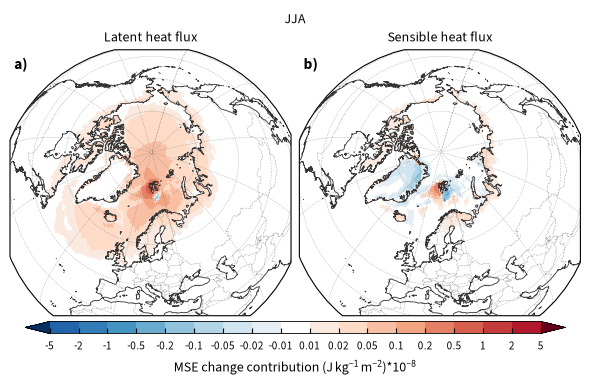

In [108]:
lonmin, lonmax = -179, 180
latmin, latmax =   30,  90

map_proj  = ccrs.NearsidePerspective(central_longitude=15, central_latitude=75)
data_proj = ccrs.PlateCarree()

CBAR_LABEL = r'MSE change contribution ($\mathrm{J\,kg^{-1}\,m^{-2}}$)'



# -- figure layout

fig, axes = plt.subplots(1, 2, figsize=(W,0.65*W),
                         subplot_kw={'projection': map_proj},
                         constrained_layout=True)
axs = axes.flatten()


def decorate(ax, title=None, label=None):
    ax.set_extent([lonmin, lonmax, latmin, latmax], crs=data_proj)
    #ax.add_feature(cfeature.LAND.with_scale('50m'),  facecolor='0.92', zorder=0)
    ax.add_feature(cfeature.OCEAN.with_scale('50m'), facecolor='white', zorder=0)
    ax.add_feature(cfeature.COASTLINE.with_scale('50m'),
                   linewidth=0.6, edgecolor='0.2', zorder=5)
    ax.add_feature(cfeature.BORDERS.with_scale('50m'),
                   linewidth=0.4, linestyle=':', edgecolor='0.4', zorder=5)
    ax.gridlines(crs=data_proj, draw_labels=False, linewidth=0.4,
                 color='grey', alpha=0.5, linestyle='--',
                 xlocs=np.arange(-180, 181, 30),
                 ylocs=np.arange(30, 91, 15), zorder=6)
    ax.spines['geo'].set_linewidth(0.8)
    if title:
        ax.set_title(title, pad=6)
    if label:
        ax.text(0.015, 0.985, label, transform=ax.transAxes,
                ha='left', va='top', fontweight='bold', fontsize=11)#,
                #bbox=dict(boxstyle='round,pad=0.25', fc='white',
                          #ec='0.5', lw=0.6, alpha=0.85), zorder=10)


panel_titles = ['Latent heat flux', 
                'Sensible heat flux']
for ax, ttl, lab in zip(axs, panel_titles, ['a)', 'b)']):
    decorate(ax, ttl, lab)


def add_cbar(mappable, ax, boundaries, label, scale=1e8, extend='both'):
    cb = fig.colorbar(mappable, ax=ax, orientation='horizontal',
                      extend=extend, fraction=0.045, pad=0.02, aspect=45,
                      ticks=boundaries)
    cb.set_label(label+r'$\mathrm{* 10^{-8}}$')# * 10$^{-8}$')
    cb.ax.set_xticklabels([f'{b * scale:g}' for b in boundaries])
    cb.ax.tick_params(labelsize=8)
    cb.outline.set_linewidth(0.6)
    return cb


m0 = map_pcolormesh(axs[0], int_lh_area, int_lh_area.longitude, int_lh_area.latitude, cmap=cmap_div, norm=norm_div)
m1 = map_pcolormesh(axs[1], int_sh_area, int_sh_area.longitude, int_sh_area.latitude, cmap=cmap_div, norm=norm_div)
add_cbar(m0, axs[:2].tolist(), bounds_div, CBAR_LABEL)

fig.suptitle('JJA')
#sm_div = plt.cm.ScalarMappable(cmap=cmap_div, norm=norm_div)
#add_cbar(sm_div, axs[:2].tolist(), bounds_div, CBAR_LABEL, extend='both')

#fig.savefig('/jetfs/home/psplechtna/plots/spatial_1991_2020_mean.pdf')

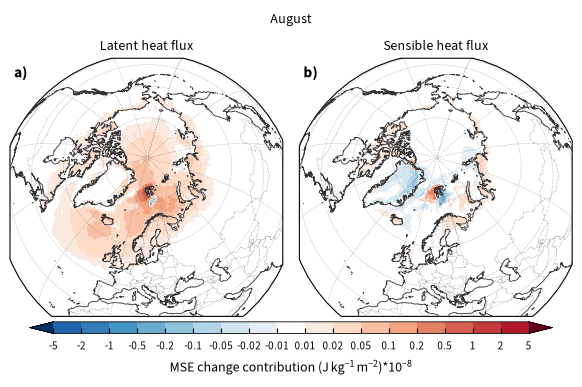

In [115]:
lonmin, lonmax = -179, 180
latmin, latmax =   30,  90

map_proj  = ccrs.NearsidePerspective(central_longitude=15, central_latitude=75)
data_proj = ccrs.PlateCarree()

CBAR_LABEL = r'MSE change contribution ($\mathrm{J\,kg^{-1}\,m^{-2}}$)'



# -- figure layout

fig, axes = plt.subplots(1, 2, figsize=(W,0.65*W),
                         subplot_kw={'projection': map_proj},
                         constrained_layout=True)
axs = axes.flatten()


def decorate(ax, title=None, label=None):
    ax.set_extent([lonmin, lonmax, latmin, latmax], crs=data_proj)
    #ax.add_feature(cfeature.LAND.with_scale('50m'),  facecolor='0.92', zorder=0)
    ax.add_feature(cfeature.OCEAN.with_scale('50m'), facecolor='white', zorder=0)
    ax.add_feature(cfeature.COASTLINE.with_scale('50m'),
                   linewidth=0.6, edgecolor='0.2', zorder=5)
    ax.add_feature(cfeature.BORDERS.with_scale('50m'),
                   linewidth=0.4, linestyle=':', edgecolor='0.4', zorder=5)
    ax.gridlines(crs=data_proj, draw_labels=False, linewidth=0.4,
                 color='grey', alpha=0.5, linestyle='--',
                 xlocs=np.arange(-180, 181, 30),
                 ylocs=np.arange(30, 91, 15), zorder=6)
    ax.spines['geo'].set_linewidth(0.8)
    if title:
        ax.set_title(title, pad=6)
    if label:
        ax.text(0.015, 0.985, label, transform=ax.transAxes,
                ha='left', va='top', fontweight='bold', fontsize=11)#,
                #bbox=dict(boxstyle='round,pad=0.25', fc='white',
                          #ec='0.5', lw=0.6, alpha=0.85), zorder=10)


panel_titles = ['Latent heat flux', 
                'Sensible heat flux']
for ax, ttl, lab in zip(axs, panel_titles, ['a)', 'b)']):
    decorate(ax, ttl, lab)


def add_cbar(mappable, ax, boundaries, label, scale=1e8, extend='both'):
    cb = fig.colorbar(mappable, ax=ax, orientation='horizontal',
                      extend=extend, fraction=0.045, pad=0.02, aspect=45,
                      ticks=boundaries)
    cb.set_label(label+r'$\mathrm{* 10^{-8}}$')# * 10$^{-8}$')
    cb.ax.set_xticklabels([f'{b * scale:g}' for b in boundaries])
    cb.ax.tick_params(labelsize=8)
    cb.outline.set_linewidth(0.6)
    return cb


m0 = map_pcolormesh(axs[0], int_lh_aug_area, int_lh_area.longitude, int_lh_area.latitude, cmap=cmap_div, norm=norm_div)
m1 = map_pcolormesh(axs[1], int_sh_aug_area, int_sh_area.longitude, int_sh_area.latitude, cmap=cmap_div, norm=norm_div)
add_cbar(m0, axs[:2].tolist(), bounds_div, CBAR_LABEL)

fig.suptitle('August')
#sm_div = plt.cm.ScalarMappable(cmap=cmap_div, norm=norm_div)
#add_cbar(sm_div, axs[:2].tolist(), bounds_div, CBAR_LABEL, extend='both')

#fig.savefig('/jetfs/home/psplechtna/plots/spatial_1991_2020_aug_mean.pdf')

In [110]:
total_mse_all = int_lh_all.sum() + int_sh_all.sum()
total_mse_aug = int_lh_aug.sum() + int_sh_aug.sum()

In [111]:
int_mse_all = int_lh_all + int_sh_all
int_mse_aug = int_lh_aug + int_sh_aug

In [112]:
# Reduce over longitude
int_mse_zonal_all = int_mse_all.sum(dim='longitude')
int_mse_zonal_aug = int_mse_aug.sum(dim='longitude')

# Define 5-degree latitude bins
lat_min = float(int_mse_zonal_all.latitude.min())
lat_max = float(int_mse_zonal_all.latitude.max())
bins = np.arange(np.floor(lat_min / 5) * 5,
                 np.ceil(lat_max / 5) * 5 + 5, 5)

# Bin by latitude
rel_mse_binned_all = (
    int_mse_zonal_all
    .groupby_bins('latitude', bins=bins, labels=(bins[:-1] + bins[1:]) / 2)
    .sum()
)

rel_mse_binned_aug = (
    int_mse_zonal_aug
    .groupby_bins('latitude', bins=bins, labels=(bins[:-1] + bins[1:]) / 2)
    .sum()
)

In [113]:
rel_mse_binned_rel = rel_mse_binned_all/total_mse_all
rel_mse_binned_rel_aug = rel_mse_binned_aug/total_mse_aug

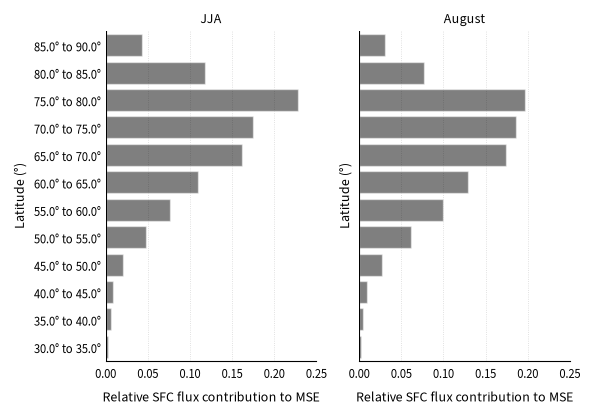

In [124]:
lats = rel_mse_binned_all.latitude_bins.values.astype(float)
vals_all = rel_mse_binned_rel.values
vals_aug = rel_mse_binned_rel_aug.values

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(1, 2, figsize=(W, 0.7*W), sharey=True)

ax[0].barh(lats, vals_all, height=4.0, align='center', color='black', alpha=0.5, edgecolor='white')
ax[0].set_title('JJA')

ax[1].barh(lats, vals_aug, height=4.0, align='center', color='black', alpha=0.5, edgecolor='white')
ax[1].set_title('August')

for axs in ax:
    for spine in ['top', 'right', 'left']:
        axs.spines[spine].set_visible(False)
    axs.set_yticks(lats)
    axs.set_yticklabels([f'{l-2.5}° to {l+2.5}°' for l in lats])
    axs.set_xlabel('Relative SFC flux contribution to MSE')
    axs.set_ylabel('Latitude (°)')
    axs.set_ylim(30, 90)
    axs.axvline(0, color='black', linewidth=0.8)
    axs.tick_params('both', length=0)
    axs.grid(axis='x', linestyle=':', linewidth=0.6, alpha=0.5)
    axs.set_axisbelow(True)
    axs.set_xlim(0,0.25)

#fig.savefig('/jetfs/home/psplechtna/plots/mean_lat.pdf')